In [1]:
#                                   ---- HOUSE PRICE PREDICTION ----
#  This project predicts the price of house based on area,no of bedrooms,no of bathrooms,no of stories ,no of parking area etc.

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error,mean_squared_error,r2_score
import tkinter as tk

In [3]:
reading_file=pd.read_csv("Housing_data.csv")

In [4]:
reading_file.head()

,price,area,bedrooms,bathrooms,stories,parking
0,13300000,7420,4,2,3,2
1,12250000,8960,4,4,4,3
2,12250000,9960,3,2,2,2
3,12215000,7500,4,2,2,3
4,11410000,7420,4,1,2,2


In [5]:
reading_file.isnull().sum() 

price        0
area         0
bedrooms     0
bathrooms    0
stories      0
parking      0
dtype: int64

In [6]:
reading_file.duplicated().sum()

np.int64(1)

In [7]:
dup_all = reading_file[reading_file.duplicated(keep=False)]
print(dup_all)

       price  area  bedrooms  bathrooms  stories  parking
366  3675000  3630         2          1        1        0
367  3675000  3630         2          1        1        0


In [8]:
reading_file = reading_file.drop_duplicates()

In [9]:
reading_file.info()

<class 'pandas.core.frame.DataFrame'>
Index: 544 entries, 0 to 544
Data columns (total 6 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   price      544 non-null    int64
 1   area       544 non-null    int64
 2   bedrooms   544 non-null    int64
 3   bathrooms  544 non-null    int64
 4   stories    544 non-null    int64
 5   parking    544 non-null    int64
dtypes: int64(6)
memory usage: 29.8 KB


In [10]:
reading_file.describe()

,price,area,bedrooms,bathrooms,stories,parking
count,5.440000e+02,544.000000,544.000000,544.000000,544.000000,544.000000
mean,4.768736e+06,5153.336397,2.966912,1.286765,1.806985,0.694853
std,1.871574e+06,2171.156248,0.737579,0.502782,0.867601,0.861864
min,1.750000e+06,1650.000000,1.000000,1.000000,1.000000,0.000000
25%,3.430000e+06,3596.000000,2.000000,1.000000,1.000000,0.000000
50%,4.340000e+06,4600.000000,3.000000,1.000000,2.000000,0.000000
75%,5.748750e+06,6360.000000,3.000000,2.000000,2.000000,1.000000
max,1.330000e+07,16200.000000,6.000000,4.000000,4.000000,3.000000


In [11]:
columns=['area','bedrooms','bathrooms','stories','parking']

x=reading_file[columns]      #independent variable
y=reading_file['price']      #dependent variable

model=LinearRegression()

model.fit(x,y)  #Train the model

predicted_y=model.predict(x)  #Predicting value


print("Mean absolute error:",mean_absolute_error(y,predicted_y))
print("Mean squared error:",mean_squared_error(y,predicted_y))
print("R2 score:",r2_score(y,predicted_y))

Mean absolute error: 909586.2773069678
Mean squared error: 1533153684123.1877
R2 score: 0.5614987191064927


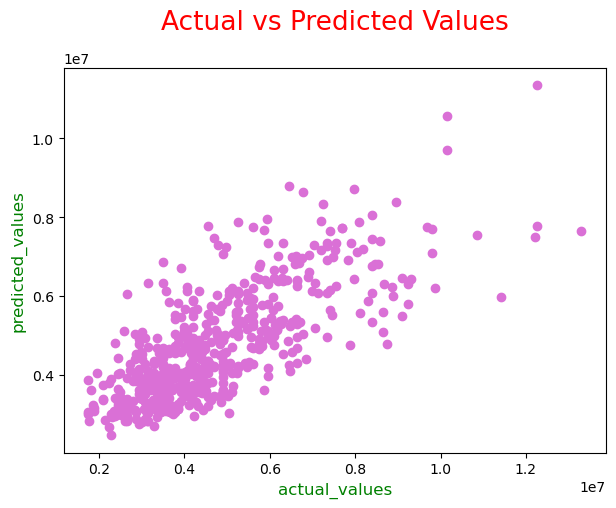

In [12]:
#Visualize the actual and predicted values to visualize accuracy

plt.figure(figsize=(7,5))
plt.scatter(y,predicted_y,color="orchid")
plt.title("Actual vs Predicted Values\n",color="red",size=19)
plt.xlabel("actual_values",color="green",size=12)
plt.ylabel("predicted_values",color="green",size=12)
plt.show()

In [13]:
root = tk.Tk()
root.title("House Price Prediction")
root.config(bg="mintcream")

def is_float(value):
    value = value.strip()              
    if not value or value[0] == '-':
        return False
    return value.replace('.', '', 1).isdigit()

def predict_price():
    area_value = entry_area.get()

    if not is_float(area_value):
        label_result.config(text="Please enter a valid numeric area.", fg="red")
        return

    area = float(area_value)
    bedrooms = slider_bedrooms.get()
    bathrooms = slider_bathrooms.get()
    stories = slider_stories.get()
    parking = slider_parking.get()

    user_data = pd.DataFrame([[area, bedrooms, bathrooms, stories, parking]], columns=columns)

    predicted_price = model.predict(user_data)[0]

    label_result.config(text=f"Predicted Price: ₹{predicted_price:,.2f}",
                        fg="darkgreen")

def clear_fields():
    entry_area.delete(0, tk.END)
    slider_bedrooms.set(1)
    slider_bathrooms.set(1)
    slider_stories.set(1)
    slider_parking.set(0)
    label_result.config(text="")

title_label = tk.Label(root, text="House Price Predictor",
                       font=("Helvetica", 28, "bold"),
                       bg="lightseagreen", fg="white", padx=20, pady=15)
title_label.pack(pady=20, fill=tk.X)

frame_inputs = tk.Frame(root, bg="honeydew", padx=40, pady=20)
frame_inputs.pack(pady=20)

tk.Label(frame_inputs, text="Area (sq.ft):", bg="honeydew", fg="darkslategray",font=("Helvetica", 14, "bold")).grid(row=0, column=0, pady=12,sticky="w")
entry_area = tk.Entry(frame_inputs, font=("Helvetica", 14), width=20)
entry_area.grid(row=0, column=1, padx=20)

tk.Label(frame_inputs, text="Bedrooms:", bg="honeydew", fg="darkslategray",font=("Helvetica", 14, "bold")).grid(row=1, column=0, pady=12, sticky="w")
slider_bedrooms = tk.Scale(frame_inputs, from_=1, to=10, orient=tk.HORIZONTAL,bg="honeydew", length=300)
slider_bedrooms.grid(row=1, column=1, padx=20)

tk.Label(frame_inputs, text="Bathrooms:", bg="honeydew", fg="darkslategray",font=("Helvetica", 14, "bold")).grid(row=2, column=0, pady=12, sticky="w")
slider_bathrooms = tk.Scale(frame_inputs, from_=1, to=10, orient=tk.HORIZONTAL,bg="honeydew", length=300)
slider_bathrooms.grid(row=2, column=1, padx=20)

tk.Label(frame_inputs, text="Stories:", bg="honeydew", fg="darkslategray",font=("Helvetica", 14, "bold")).grid(row=3, column=0, pady=12, sticky="w")
slider_stories = tk.Scale(frame_inputs, from_=1, to=5, orient=tk.HORIZONTAL, bg="honeydew", length=300)
slider_stories.grid(row=3, column=1, padx=20)

tk.Label(frame_inputs, text="Parking:", bg="honeydew", fg="darkslategray",font=("Helvetica", 14, "bold")).grid(row=4, column=0, pady=12, sticky="w")
slider_parking = tk.Scale(frame_inputs, from_=0, to=5, orient=tk.HORIZONTAL,bg="honeydew", length=300)
slider_parking.grid(row=4, column=1, padx=20)

frame_buttons = tk.Frame(root, bg="mintcream")
frame_buttons.pack(pady=30)

tk.Button(frame_buttons, text="Predict Price", command=predict_price,bg="seagreen", fg="white", font=("Helvetica", 16, "bold"),
          width=15, height=2).grid(row=0, column=0, padx=25)

tk.Button(frame_buttons, text="Clear", command=clear_fields,bg="indianred", fg="white", font=("Helvetica", 16, "bold"),
          width=15, height=2).grid(row=0, column=1, padx=25)

label_result = tk.Label(root, text="", bg="mintcream",font=("Helvetica", 18, "bold"))
label_result.pack(pady=40)

root.mainloop()